# AI 앙상블 기반 동적 최적 경로 탐색 시스템
- **VOL** : BO 가중치 앙상블 (LSTM + Transformer)
- **SPD / OCC** : Ridge 스태킹 앙상블
- **알고리즘** : Dijkstra (5분 주기 재탐색)
- **사고율** : ROUTE_ID(4종) × 요일 × 월 × 시간대 별 독립 테이블

> **실행 순서**: 섹션 0~4 셀을 모두 실행 → 마지막 셀(섹션 9) 실행

## 섹션 0. 라이브러리 및 경로 설정

In [1]:
import os, math, pickle, heapq, time, warnings
import numpy as np
import torch
import torch.nn as nn
from datetime import datetime
from collections import deque
warnings.filterwarnings('ignore')

import sys
from datetime import datetime
from PyQt5.QtWidgets import (QApplication, QWidget, QLabel, QVBoxLayout, 
                             QHBoxLayout, QPushButton, QLineEdit, QTextEdit, QFrame)
from PyQt5.QtGui import QPixmap, QFont
from PyQt5.QtCore import Qt

# ⚙️ 모델 파일 폴더 경로 ─────────────────────────────────────────
MODEL_DIR = r"D:\\엔지니어링 공모전\\python_code\\second_program"  # ← 수정

LSTM_MODEL_PATH  = os.path.join(MODEL_DIR, 'best_lstm_model.pt')
TR_MODEL_PATH    = os.path.join(MODEL_DIR, 'best_transformer_model.pt')
SCALERS_PATH     = os.path.join(MODEL_DIR, 'scalers.pkl')
ENCODERS_PATH    = os.path.join(MODEL_DIR, 'encoders.pkl')
LSTM_CFG_PATH    = os.path.join(MODEL_DIR, 'model_config.pkl')
TR_CFG_PATH      = os.path.join(MODEL_DIR, 'tr_model_config.pkl')
ENS_WEIGHTS_PATH = os.path.join(MODEL_DIR, 'bo_best_weights.npy')
RIDGE_PATH       = os.path.join(MODEL_DIR, 'ridge_model.pkl')

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEQ_LEN = 12  # 과거 12 타임스텝 (1시간)

print(f'디바이스: {DEVICE}')
print('경로 설정 완료')

디바이스: cuda
경로 설정 완료


## 섹션 1. 그래프 정의 ← 직접 수정하는 영역

In [4]:
# ══════════════════════════════════════════════════════════════
# 노드 이름 (자유롭게 변경 가능)
# ══════════════════════════════════════════════════════════════
NODE_NAMES = ['N1', 'N2', 'N3', 'N4', 'N5', 'N6', 'N7', 'N8', 'N9']

# ══════════════════════════════════════════════════════════════
# 엣지별 거리 (km) ← 실제 거리로 수정
# 방향이 다르면 별도 항목으로 입력
# ══════════════════════════════════════════════════════════════
EDGE_DISTANCES = {
    ('N1', 'N2'): 2.7,
    ('N2', 'N1'): 2.7,
    ('N2', 'N3'): 15.0,
    ('N3', 'N2'): 15.0,
    ('N3', 'N4'): 1.9,
    ('N4', 'N3'): 1.9,
    ('N3', 'N9'): 7.9,
    ('N9', 'N3'): 7.9,
    ('N4', 'N5'): 7.4,
    ('N5', 'N4'): 7.4,
    ('N4', 'N6'): 9.7,
    ('N6', 'N4'): 9.7,
    ('N5', 'N6'): 3.1,
    ('N6', 'N5'): 3.1,
    ('N6', 'N7'): 8.2,
    ('N7', 'N6'): 8.2,
    ('N2', 'N5'): 15.7,
    ('N5', 'N2'): 15.7,
    ('N6', 'N8'): 3.2,
    ('N8', 'N6'): 3.2,
}

# ══════════════════════════════════════════════════════════════
# 엣지별 (ROUTE_ID, LINK_ID) 목록 ← 실제 값으로 수정
# 방향이 다르면 별도 항목 (ROUTE_ID/LINK_ID가 반드시 달라짐)
# 구간이 여러 개면 리스트에 추가 → 예측값 평균 적용
# ══════════════════════════════════════════════════════════════
EDGE_LINKS = {
    ('N1', 'N2'): [('LKR3000010', 'LKR2000040')],
    ('N2', 'N1'): [('LKL3000010', 'LKL2000020')],
    ('N2', 'N3'): [('LKL3000010', 'LKI2000170'), ('LKL3000010', 'LKI2000160'), ('LKL3000010', 'LKI2000150'), ('LKL3000010', 'LKI2000140'), ('LKL3000010', 'LKI2000130'), ('LKL3000010', 'LKI2000120'), ('LKL3000010', 'LKI2000110'), ('LKL3000010', 'LKI2000100'), ('LKL3000010', 'LKL2000105')],
    ('N3', 'N2'): [('LKR3000010', 'LKO2000120'), ('LKR3000010', 'LKO2000110'), ('LKR3000010', 'LKO2000100'), ('LKR3000010', 'LKO2000090'), ('LKR3000010', 'LKO2000080'), ('LKR3000010', 'LKO2000070'), ('LKR3000010', 'LKO2000060'), ('LKR3000010', 'LKO2000050'), ('LKR3000010', 'LKO2000040')],
    ('N3', 'N4'): [('LDI3000010', 'LDI2000020')],
    ('N4', 'N3'): [('LDI3000010', 'LDI2000020')],
    ('N3', 'N9'): [('LKR3000010', 'LKR2000155'), ('LKR3000010', 'LKR2000170'), ('LKR3000010', 'LKR2000180'), ('LKR3000010', 'LKR2000190'), ('LKR3000010', 'LKR2000200'), ('LKR3000010', 'LKR2000210')],
    ('N9', 'N3'): [('LKL3000010', 'LKL2000050'), ('LKL3000010', 'LKL2000060'), ('LKL3000010', 'LKL2000070'), ('LKL3000010', 'LKL2000080'), ('LKL3000010', 'LKL2000090'), ('LKL3000010', 'LKL2000100')],
    ('N4', 'N5'): [('LRO3000010', 'LRO2000050'), ('LRO3000010', 'LRO2000040'), ('LRO3000010', 'LRO2000025')],
    ('N5', 'N4'): [('LRI3000010', 'LRI2000150'), ('LRI3000010', 'LRI2000135'), ('LRI3000010', 'LRI2000120'), ('LRI3000010', 'LRI2000110')],
    ('N4', 'N6'): [('LDO3000010', 'LDO2000050'), ('LDO3000010', 'LDO2000060'), ('LDO3000010', 'LDO2000070'), ('LDO3000010', 'LDO2000080')],
    ('N6', 'N4'): [('LDI3000010', 'LDI2000070'), ('LDI3000010', 'LDI2000083'), ('LDI3000010', 'LDI2000085'), ('LDI3000010', 'LDI2000090')],
    ('N5', 'N6'): [('LBR3000010', 'LBR2000020')],
    ('N6', 'N5'): [('LBL3000010', 'LBL2000050')],
    ('N6', 'N7'): [('LDO3000010', 'LDO2000090'), ('LDO3000010', 'LDO2000100'), ('LDO3000010', 'LDO2000110'), ('LDO3000010', 'LDO2000120'), ('LDO3000010', 'LDO2000130'), ('LDO3000010', 'LDO2000140'), ('LDO3000010', 'LDO2000145')],
    ('N7', 'N6'): [('LDI3000010', 'LDI2000015'), ('LDI3000010', 'LDI2000025'), ('LDI3000010', 'LDI2000030'), ('LDI3000010', 'LDI2000040'), ('LDI3000010', 'LDI2000050'), ('LDI3000010', 'LDI2000060')],
    ('N2', 'N5'): [('LRI3000010', 'LRI2000100'), ('LRI3000010', 'LRI2000090'), ('LRI3000010', 'LRI2000080'), ('LRI3000010', 'LRI2000070'), ('LRI3000010', 'LRI2000060'), ('LRI3000010', 'LRI2000050'), ('LRI3000010', 'LRI2000040'), ('LRI3000010', 'LRI2000030'), ('LRI3000010', 'LRI2000020')],
    ('N5', 'N2'): [('LRO3000010', 'LRO2000150'), ('LRO3000010', 'LRO2000140'), ('LRO3000010', 'LRO2000130'), ('LRO3000010', 'LRO2000120'), ('LRO3000010', 'LRO2000110'), ('LRO3000010', 'LRO2000100'), ('LRO3000010', 'LRO2000090'), ('LRO3000010', 'LRO2000085'), ('LRO3000010', 'LRO2000083'), ('LRO3000010', 'LRO2000070'), ('LRO3000010', 'LRO2000060')],
    ('N6', 'N8'): [('LBR3000010', 'LBR2000030'), ('LBR3000010', 'LBR2000040'), ('LBR3000010', 'LBR2000050')],
    ('N8', 'N6'): [('LBL3000010', 'LBL2000020'), ('LBL3000010', 'LBL2000030')],
}

print('그래프 정의 완료')
print(f'  노드 수: {len(NODE_NAMES)}')
print(f'  엣지 수: {len(EDGE_DISTANCES)}')

그래프 정의 완료
  노드 수: 9
  엣지 수: 20


## 섹션 2. 사고율 테이블 (ROUTE_ID 4종 × 요일/월/시간) ← 직접 수정하는 영역

In [5]:
# ══════════════════════════════════════════════════════════════
# ROUTE_ID 4종에 따른 사고율 테이블
# ← 실제 데이터 기반 값으로 각 ROUTE_ID별로 수정하세요
# ══════════════════════════════════════════════════════════════

# ── ROUTE_ID별 요일 사고율 (0=월 ~ 6=일) ──────────────────────
ACC_WEEKDAY_BY_ROUTE = {
    'LKR3000010': {0:0.693931398, 1:0.841688654, 2:0.833773087, 3:0.828496042, 4:0.873350923, 5:1, 6:0.957783641}, 
    'LKL3000010': {0:0.693931398, 1:0.841688654, 2:0.833773087, 3:0.828496042, 4:0.873350923, 5:1, 6:0.957783641},
    'LRO3000010': {0:0.743421053, 1:0.710526316, 2:1, 3:0.848684211, 4:0.842105263, 5:0.986842105, 6:0.960526316},
    'LRI3000010': {0:0.743421053, 1:0.710526316, 2:1, 3:0.848684211, 4:0.842105263, 5:0.986842105, 6:0.960526316},
    'LDI3000010': {0:0.940828402, 1:0.840236686, 2:0.816568047, 3:0.98816568, 4:0.958579882, 5:1, 6:0.976331361},
    'LDO3000010': {0:0.940828402, 1:0.840236686, 2:0.816568047, 3:0.98816568, 4:0.958579882, 5:1, 6:0.976331361},
    'LBR3000010': {0:0.511111111, 1:0.577777778, 2:0.533333333, 3:0.422222222, 4:0.488888889, 5:0.977777778, 6:1},
    'LBL3000010': {0:0.511111111, 1:0.577777778, 2:0.533333333, 3:0.422222222, 4:0.488888889, 5:0.977777778, 6:1},
}

# ── ROUTE_ID별 월별 사고율 (1~12월) ────────────────────────────
ACC_MONTH_BY_ROUTE = {
    'LKR3000010': {1:0.815384615,2:0.784615385,3:0.711538462,4:0.684615385,5:0.65,6:0.634615385,
                   7:0.561538462,8:0.588461538,9:0.746153846,10:0.815384615,11:0.796153846,12:1},
    'LKL3000010': {1:0.815384615,2:0.784615385,3:0.711538462,4:0.684615385,5:0.65,6:0.634615385,
                   7:0.561538462,8:0.588461538,9:0.746153846,10:0.815384615,11:0.796153846,12:1},
    'LRO3000010': {1:0.743119266,2:0.660550459,3:0.633027523,4:0.651376147,5:0.724770642,6:0.660550459,
                   7:0.550458716,8:0.596330275,9:0.834862385,10:0.633027523,11:0.80733945,12:1},
    'LRI3000010': {1:0.743119266,2:0.660550459,3:0.633027523,4:0.651376147,5:0.724770642,6:0.660550459,
                   7:0.550458716,8:0.596330275,9:0.834862385,10:0.633027523,11:0.80733945,12:1},
    'LDO3000010': {1:0.831858407,2:0.867256637,3:0.743362832,4:0.769911504,5:0.938053097,6:0.690265487,
                   7:0.814159292,8:0.522123894,9:0.814159292,10:0.89380531,11:0.867256637,12:1},
    'LDI3000010': {1:0.831858407,2:0.867256637,3:0.743362832,4:0.769911504,5:0.938053097,6:0.690265487,
                   7:0.814159292,8:0.522123894,9:0.814159292,10:0.89380531,11:0.867256637,12:1},
    'LBR3000010': {1:0.695652174,2:0.956521739,3:0.869565217,4:0.739130435,5:0.652173913,6:0.565217391,
                   7:0.565217391,8:1,9:0.826086957,10:0.739130435,11:0.565217391,12:0.652173913},
    'LBL3000010': {1:0.695652174,2:0.956521739,3:0.869565217,4:0.739130435,5:0.652173913,6:0.565217391,
                   7:0.565217391,8:1,9:0.826086957,10:0.739130435,11:0.565217391,12:0.652173913},
}

# ── ROUTE_ID별 시간대별 사고율 ─────────────────────────────────
# 함수 형태로 정의: (route_id, hour) → acc_hour
def get_hour_rate(route_id: str, hour: int) -> float:
    """
    ROUTE_ID와 시간(0~23)에 따라 시간대별 사고율 반환
    ← 각 ROUTE_ID별로 실제 데이터 기반 값으로 수정하세요
    """
    if (route_id == 'LKR3000010') or (route_id == 'LKL3000010'): 
        if   0 <= hour < 1:   return 0.095744681
        elif 1 <= hour < 2: return 0.079787234
        elif 2 <= hour < 3: return 0.069148936
        elif 3 <= hour < 4: return 0.026595745
        elif 4 <= hour < 5: return 0.031914894
        elif 5 <= hour < 6: return 0.191489362
        elif 6 <= hour < 7: return 0.324468085
        elif 7 <= hour < 8: return 0.340425532
        elif 8 <= hour < 9: return 0.643617021
        elif 9 <= hour < 10: return 0.723404255
        elif 10 <= hour < 11: return 0.686170213
        elif 11 <= hour < 12: return 0.590425532
        elif 12 <= hour < 13: return 0.787234043
        elif 13 <= hour < 14: return 0.792553191
        elif 14 <= hour < 15: return 0.936170213
        elif 15 <= hour < 16: return 0.968085106
        elif 16 <= hour < 17: return 0.909574468
        elif 17 <= hour < 18: return 1
        elif 18 <= hour < 19: return 0.670212766
        elif 19 <= hour < 20: return 0.808510638
        elif 20 <= hour < 21: return 0.489361702
        elif 21 <= hour < 22: return 0.473404255
        elif 22 <= hour < 23: return 0.340425532
        elif 23 <= hour < 24: return 0.175531915
        else:                  return 0.175531915

    elif (route_id == 'LRO3000010') or (route_id == 'LRI3000010'):           # ← ROUTE_ID 1 시간대별 사고율
        if   0 <= hour < 1:   return 0.076271186
        elif 1 <= hour < 2: return 0.06779661
        elif 2 <= hour < 3: return 0.016949153
        elif 3 <= hour < 4: return 0.042372881
        elif 4 <= hour < 5: return 0.008474576
        elif 5 <= hour < 6: return 0.06779661
        elif 6 <= hour < 7: return 0.169491525
        elif 7 <= hour < 8: return 0.237288136
        elif 8 <= hour < 9: return 0.474576271
        elif 9 <= hour < 10: return 0.381355932
        elif 10 <= hour < 11: return 0.398305085
        elif 11 <= hour < 12: return 0.322033898
        elif 12 <= hour < 13: return 0.43220339
        elif 13 <= hour < 14: return 0.389830508
        elif 14 <= hour < 15: return 0.525423729
        elif 15 <= hour < 16: return 0.788135593
        elif 16 <= hour < 17: return 0.661016949
        elif 17 <= hour < 18: return 1
        elif 18 <= hour < 19: return 0.652542373
        elif 19 <= hour < 20: return 0.406779661
        elif 20 <= hour < 21: return 0.262711864
        elif 21 <= hour < 22: return 0.152542373
        elif 22 <= hour < 23: return 0.194915254
        elif 23 <= hour < 24: return 0.118644068
        else:                  return 0.118644068

    elif (route_id == 'LDO3000010') or (route_id == 'LDI3000010'):           # ← ROUTE_ID 1 시간대별 사고율
        if   0 <= hour < 1:   return 0.155555556
        elif 1 <= hour < 2: return 0.111111111
        elif 2 <= hour < 3: return 0.044444444
        elif 3 <= hour < 4: return 0.055555556
        elif 4 <= hour < 5: return 0.111111111
        elif 5 <= hour < 6: return 0.344444444
        elif 6 <= hour < 7: return 0.422222222
        elif 7 <= hour < 8: return 0.411111111
        elif 8 <= hour < 9: return 0.755555556
        elif 9 <= hour < 10: return 0.933333333
        elif 10 <= hour < 11: return 0.566666667
        elif 11 <= hour < 12: return 0.588888889
        elif 12 <= hour < 13: return 0.6
        elif 13 <= hour < 14: return 0.655555556
        elif 14 <= hour < 15: return 0.9
        elif 15 <= hour < 16: return 0.966666667
        elif 16 <= hour < 17: return 0.855555556
        elif 17 <= hour < 18: return 1
        elif 18 <= hour < 19: return 0.588888889
        elif 19 <= hour < 20: return 0.611111111
        elif 20 <= hour < 21: return 0.511111111
        elif 21 <= hour < 22: return 0.322222222
        elif 22 <= hour < 23: return 0.444444444
        elif 23 <= hour < 24: return 0.288888889
        else:                  return 0.288888889

    else:  # 미등록 ROUTE_ID 기본값
        if   0 <= hour < 1:   return 0.15
        elif 1 <= hour < 2: return 0.05
        elif 2 <= hour < 3: return 0.15
        elif 3 <= hour < 4: return 0
        elif 4 <= hour < 5: return 0.15
        elif 5 <= hour < 6: return 0.15
        elif 6 <= hour < 7: return 0.25
        elif 7 <= hour < 8: return 0.05
        elif 8 <= hour < 9: return 0.6
        elif 9 <= hour < 10: return 0.7
        elif 10 <= hour < 11: return 0.6
        elif 11 <= hour < 12: return 0.4
        elif 12 <= hour < 13: return 0.4
        elif 13 <= hour < 14: return 0.5
        elif 14 <= hour < 15: return 0.45
        elif 15 <= hour < 16: return 1
        elif 16 <= hour < 17: return 0.8
        elif 17 <= hour < 18: return 1
        elif 18 <= hour < 19: return 0.85
        elif 19 <= hour < 20: return 0.45
        elif 20 <= hour < 21: return 0.65
        elif 21 <= hour < 22: return 0.35
        elif 22 <= hour < 23: return 0.2
        elif 23 <= hour < 24: return 0.25
        else:                  return 0.25


def get_acc_rates(edge: tuple, route_id: str,
                  weekday: int, month: int, hour: int) -> tuple:
    """
    (출발, 도착) 엣지, ROUTE_ID, 시간 정보를 받아
    (acc_weekday, acc_month, acc_hour) 반환
    """
    wd_table = ACC_WEEKDAY_BY_ROUTE.get(
        route_id, ACC_WEEKDAY_BY_ROUTE['LRO3000010']
    )
    mo_table = ACC_MONTH_BY_ROUTE.get(
        route_id, ACC_MONTH_BY_ROUTE['LRO3000010']
    )

    acc_weekday = wd_table.get(weekday, 0.12)
    acc_month   = mo_table.get(month,   0.11)
    acc_hour    = get_hour_rate(route_id, hour)

    return acc_weekday, acc_month, acc_hour


print('사고율 테이블 정의 완료')
# 확인 출력
for rid in list(ACC_WEEKDAY_BY_ROUTE.keys()):
    wd, mo, hr = get_acc_rates(('N1','N2'), rid, 4, 5, 8)
    print(f'  {rid} | 금요일 5월 08시 → wd={wd:.3f}, mo={mo:.3f}, hr={hr:.3f}')

사고율 테이블 정의 완료
  LKR3000010 | 금요일 5월 08시 → wd=0.873, mo=0.650, hr=0.644
  LKL3000010 | 금요일 5월 08시 → wd=0.873, mo=0.650, hr=0.644
  LRO3000010 | 금요일 5월 08시 → wd=0.842, mo=0.725, hr=0.475
  LRI3000010 | 금요일 5월 08시 → wd=0.842, mo=0.725, hr=0.475
  LDI3000010 | 금요일 5월 08시 → wd=0.959, mo=0.938, hr=0.756
  LDO3000010 | 금요일 5월 08시 → wd=0.959, mo=0.938, hr=0.756
  LBR3000010 | 금요일 5월 08시 → wd=0.489, mo=0.652, hr=0.600
  LBL3000010 | 금요일 5월 08시 → wd=0.489, mo=0.652, hr=0.600


In [6]:
# ⚙️ 공휴일 날짜 목록 — 2026년 기준 (월, 일)
HOLIDAYS = {
    (1,  1), (2,  16), (2,  17), (2,  18),  
    (3,  1), (3,  2),  
    (5,  5), (5,  24), (5,  25), 
    (6,  3), (6,  6), (7,  17),  
    (8, 15), (8,  17), (9,  24), (9,  25),
    (9,  26), (10, 3), (10,  3), (10,  5), 
    (10, 9), 
    (12, 25),  
}

def check_holiday() -> int:
    """오늘 날짜가 공휴일이면 1, 아니면 0 반환"""
    today = datetime.now()
    return 1 if (today.month, today.day) in HOLIDAYS else 0

## 섹션 3. 모델 클래스 정의

In [7]:
class TrafficLSTM(nn.Module):
    def __init__(self, num_numeric_features, num_routes, route_emb_dim,
                 num_links, link_emb_dim, hidden_size=128, num_layers=1,
                 dropout=0.1, output_size=3, pred_steps=3):
        super().__init__()
        self.route_emb = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb  = nn.Embedding(num_links,  link_emb_dim)
        lstm_input_dim = num_numeric_features + route_emb_dim + link_emb_dim
        self.lstm = nn.LSTM(input_size=lstm_input_dim, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(64, output_size * pred_steps)
        )
    def forward(self, x_num, x_cat):
        route_e = self.route_emb(x_cat[:, 0])
        link_e  = self.link_emb(x_cat[:, 1])
        cat_e   = torch.cat([route_e, link_e], dim=-1)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)
        x       = torch.cat([x_num, cat_e], dim=-1)
        out, _  = self.lstm(x)
        return self.fc(self.dropout(out[:, -1, :]))


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float()
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))
    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class TrafficTransformer(nn.Module):
    def __init__(self, num_numeric_features, num_routes, route_emb_dim,
                 num_links, link_emb_dim, d_model=256, nhead=4,
                 num_layers=2, dim_ff=512, dropout=0.05,
                 output_size=3, pred_steps=3):
        super().__init__()
        self.route_emb  = nn.Embedding(num_routes, route_emb_dim)
        self.link_emb   = nn.Embedding(num_links,  link_emb_dim)
        input_dim       = num_numeric_features + route_emb_dim + link_emb_dim
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_enc    = PositionalEncoding(d_model, dropout=dropout)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
            dropout=dropout, batch_first=True, norm_first=True)
        self.transformer_enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Sequential(
            nn.LayerNorm(d_model), nn.Linear(d_model, d_model // 2),
            nn.GELU(), nn.Dropout(dropout),
            nn.Linear(d_model // 2, output_size * pred_steps)
        )
    def forward(self, x_num, x_cat):
        route_e = self.route_emb(x_cat[:, 0])
        link_e  = self.link_emb(x_cat[:, 1])
        cat_e   = torch.cat([route_e, link_e], dim=-1)
        cat_e   = cat_e.unsqueeze(1).expand(-1, x_num.size(1), -1)
        x       = self.input_proj(torch.cat([x_num, cat_e], dim=-1))
        x       = self.transformer_enc(self.pos_enc(x))
        return self.head(x[:, -1, :])

print('모델 클래스 정의 완료')

모델 클래스 정의 완료


## 섹션 4. 모델 로드 및 핵심 함수 정의

In [8]:
# ══════════════════════════════════════════════════════════════════
# 섹션 4. 모델 로드 및 핵심 함수 정의
# ══════════════════════════════════════════════════════════════════
def load_models():
    print('모델 및 스케일러 로딩 중...')
    with open(SCALERS_PATH,  'rb') as f: scalers   = pickle.load(f)
    with open(ENCODERS_PATH, 'rb') as f: encoders  = pickle.load(f)
    with open(LSTM_CFG_PATH, 'rb') as f: lstm_cfg  = pickle.load(f)
    with open(TR_CFG_PATH,   'rb') as f: tr_cfg    = pickle.load(f)

    lstm_model = TrafficLSTM(
        num_numeric_features=lstm_cfg['num_numeric_features'],
        num_routes=lstm_cfg['num_routes'],     route_emb_dim=lstm_cfg['route_emb_dim'],
        num_links=lstm_cfg['num_links'],       link_emb_dim=lstm_cfg['link_emb_dim'],
        hidden_size=lstm_cfg['hidden_size'],   num_layers=lstm_cfg['num_layers'],
        dropout=lstm_cfg['dropout'],           output_size=lstm_cfg['output_size'],
        pred_steps=lstm_cfg['pred_steps']
    ).to(DEVICE)
    lstm_model.load_state_dict(torch.load(LSTM_MODEL_PATH, map_location=DEVICE))
    lstm_model.eval()

    tr_model = TrafficTransformer(
        num_numeric_features=tr_cfg['num_numeric_features'],
        num_routes=tr_cfg['num_routes'],       route_emb_dim=tr_cfg['route_emb_dim'],
        num_links=tr_cfg['num_links'],         link_emb_dim=tr_cfg['link_emb_dim'],
        d_model=tr_cfg['d_model'],             nhead=tr_cfg['nhead'],
        num_layers=tr_cfg['num_layers'],       dim_ff=tr_cfg['dim_ff'],
        dropout=tr_cfg['dropout'],             output_size=tr_cfg['output_size'],
        pred_steps=tr_cfg['pred_steps']
    ).to(DEVICE)
    tr_model.load_state_dict(torch.load(TR_MODEL_PATH, map_location=DEVICE))
    tr_model.eval()

    bo_weights  = np.load(ENS_WEIGHTS_PATH)
    with open(RIDGE_PATH, 'rb') as f: ridge_model = pickle.load(f)

    print(f'  디바이스: {DEVICE}')
    print(f'  LSTM  파라미터: {sum(p.numel() for p in lstm_model.parameters()):,}')
    print(f'  TR    파라미터: {sum(p.numel() for p in tr_model.parameters()):,}')
    print('로딩 완료!')
    return lstm_model, tr_model, scalers, encoders, bo_weights, ridge_model

# ── 전처리: 단일 타임스텝 22차원 피처 벡터 생성 ──────────────────
def make_feature_vector(vol, spd, occ, past_spd, dt,
                        acc_weekday, acc_month, acc_hour,
                        rain, snow, visibility, is_holiday, scalers):
    vol_sc      = scalers['VOL'].transform([[np.log1p(vol)]])[0, 0]
    spd_sc      = scalers['SPD'].transform([[spd]])[0, 0]
    occ_sc      = scalers['OCC'].transform([[np.log1p(occ)]])[0, 0]
    past_spd_sc = scalers['Past_SPD'].transform([[past_spd]])[0, 0]

    doy      = dt.timetuple().tm_yday
    hour_val = dt.hour + dt.minute / 60.0
    day_sin  = math.sin(2 * math.pi * doy / 365)
    day_cos  = math.cos(2 * math.pi * doy / 365)
    hour_sin = math.sin(2 * math.pi * hour_val / 24)
    hour_cos = math.cos(2 * math.pi * hour_val / 24)

    acc_wd_sc = scalers['acc_weekday'].transform([[acc_weekday]])[0, 0]
    acc_mo_sc = scalers['acc_month'].transform([[acc_month]])[0, 0]
    acc_hr_sc = scalers['acc_hour'].transform([[acc_hour]])[0, 0]

    k_rain = '강수량(mm)'.replace('(','').replace(')','').replace('/','')  # 강수량mm
    k_snow = '적설(cm)'.replace('(','').replace(')','').replace('/','')   # 적설cm
    rain_sc = scalers[k_rain].transform([[np.log1p(rain)]])[0, 0]
    snow_sc = scalers[k_snow].transform([[np.log1p(snow)]])[0, 0]
    vis_sc  = np.log1p(visibility)

    weekday = dt.weekday()
    wd_ohe  = [1.0 if i == weekday else 0.0 for i in range(7)]

    return np.array([
        vol_sc, spd_sc, occ_sc,
        day_sin, day_cos, hour_sin, hour_cos,
        past_spd_sc,
        acc_wd_sc, acc_mo_sc, acc_hr_sc,
        rain_sc, snow_sc, vis_sc,
        float(is_holiday),
    ] + wd_ohe, dtype=np.float32)  # (22,)


# ── 순환 버퍼: 엣지별 과거 SEQ_LEN 피처 시퀀스 관리 ─────────────
# 성능 개선: 매 루프마다 동일 값 반복 대신 엣지별 이력 누적
class EdgeHistoryBuffer:
    """
    엣지별로 최근 SEQ_LEN 타임스텝의 피처를 순환 버퍼로 관리.
    초기에는 첫 피처를 SEQ_LEN번 반복 → 매 5분마다 새 피처 추가.
    """
    def __init__(self, edge_keys, seq_len=12, feat_dim=22):
        self.seq_len  = seq_len
        self.feat_dim = feat_dim
        self.buffers  = {e: None for e in edge_keys}

    def push(self, edge, feat_vec):
        """새 타임스텝 피처 추가 (deque 방식)"""
        if self.buffers[edge] is None:
            # 첫 진입: SEQ_LEN번 반복으로 초기화
            arr = np.stack([feat_vec] * self.seq_len, axis=0)
            self.buffers[edge] = deque(arr.tolist(), maxlen=self.seq_len)
        else:
            self.buffers[edge].append(feat_vec.tolist())

    def get(self, edge):
        """(SEQ_LEN, feat_dim) 배열 반환"""
        if self.buffers[edge] is None:
            raise ValueError(f'Edge {edge} not initialized — push() 먼저 호출 필요')
        return np.array(self.buffers[edge], dtype=np.float32)


# ── AI 앙상블 예측 함수 ──────────────────────────────────────────
@torch.no_grad()
def predict_edge(edge, history_feats, scalers, encoders,
                 lstm_model, tr_model, bo_weights, ridge_model):
    """
    엣지에 속한 모든 LINK_ID 예측값의 평균 반환
    Returns: {'vol': float, 'spd': float, 'occ': float}
    """
    links = EDGE_LINKS.get(edge, [])
    if not links:
        return {'vol': 100.0, 'spd': 80.0, 'occ': 5.0}

    route_enc = encoders['route_enc']
    link_enc  = encoders['link_enc']
    vol_preds, spd_preds, occ_preds = [], [], []

    for route_id_str, link_id_str in links:
        try:  r_enc = int(route_enc.transform([route_id_str])[0])
        except: r_enc = 0
        try:  l_enc = int(link_enc.transform([link_id_str])[0])
        except: l_enc = 0

        x_num = torch.tensor(history_feats[np.newaxis], dtype=torch.float32).to(DEVICE)
        x_cat = torch.tensor([[r_enc, l_enc]], dtype=torch.long).to(DEVICE)

        lstm_out   = lstm_model(x_num, x_cat).cpu().numpy()[0]   # (9,)
        tr_out     = tr_model(x_num, x_cat).cpu().numpy()[0]     # (9,)
        meta_feat  = np.concatenate([lstm_out, tr_out])[np.newaxis]  # (1,18)

        # VOL: BO 앙상블
        bo_pred    = bo_weights * lstm_out + (1 - bo_weights) * tr_out
        # SPD/OCC: Ridge 앙상블
        ridge_pred = ridge_model.predict(meta_feat)[0]

        # t+1(index=0) 기준 역변환
        vol_raw = float(np.expm1(scalers['VOL'].inverse_transform([[bo_pred[0]]])[0, 0]))
        spd_raw = float(scalers['SPD'].inverse_transform([[ridge_pred[1]]])[0, 0])
        occ_raw = float(np.expm1(scalers['OCC'].inverse_transform([[ridge_pred[2]]])[0, 0]))

        # 물리적 범위 클리핑
        vol_raw = max(0.0, vol_raw)
        spd_raw = max(1.0, min(spd_raw, 120.0))
        occ_raw = max(0.0, min(occ_raw, 100.0))

        vol_preds.append(vol_raw)
        spd_preds.append(spd_raw)
        occ_preds.append(occ_raw)

    return {
        'vol': float(np.mean(vol_preds)),
        'spd': float(np.mean(spd_preds)),
        'occ': float(np.mean(occ_preds)),
    }


# ════════════════════════════════════════════════════════════════
# ⚙️ BPR 비용 함수 파라미터 — 필요 시 수정
# ════════════════════════════════════════════════════════════════
BPR_ALPHA     = 0.15    # BPR α: 용량 초과 시 지연 강도 (교통공학 표준값)
BPR_BETA      = 5.0     # BPR β: 혼잡 민감도 지수 (표준값 4.0) \
# 기존 미국 연방고속도로국(FHWA)의 표준 Beta 값은 4.0입니다. 
# 하지만 서울의 도심고속도로는 교통량이 용량(V/C = 1.0)에 도달하는 순간, 
# 속도가 서서히 줄어드는 것이 아니라 병목 현상으로 인해 일순간에 마비(Breakdown)되는 특성이 강합니다.
# 이를 수학적으로 모사하기 위해 지수 값을 5.0으로 높여, V/C 비율이 1을 넘을 때 소요 시간이 더욱 가파르게 치솟도록 설계했습니다.
                        #        클수록 고점유율 구간 패널티 지수적 증가
LINK_CAPACITY = 670.0   # 링크 용량 (대/5분) — 도로 등급에 따라 수정
# 근거: 한국도로용량편람(KHCM)상 도시고속도로 1개 차로의 최대 통과 능력은 시간당 약 2,000대입니다. 
# 서울의 주요 간선도로가 평균 편도 4차로임을 감안하면 1시간 최대 용량은 8,000대입니다. 
# 이를 모델의 예측 주기인 5분 단위로 환산하면 약 667대(8,000 ÷ 12)가 되므로, 670대로 설정하는 것이 가장 정확합니다.
FREE_FLOW_SPD = 80.0    # 근거: 올림픽대로, 강변북로, 
# 내부순환로 등 서울시 주요 도심고속도로의 실제 최고 제한속도인 80km/h를 자유류 속도(차가 하나도 없을 때의 속도)로 
# 설정하여 현실성을 부여했습니다.
RELIABILITY_W = 0.3     # 신뢰도 패널티 가중치 (0~1)
                        #   정체일수록 도착시간 불확실 → 추가 비용
ACCIDENT_W    = 0.15    # 사고 위험 패널티 가중치 (0~1)
# 근거: 상용 내비게이션(티맵, 카카오 등)에 익숙한 국내 운전자들은 1~2분의 차이에도 민감하며, 
# 정체로 인한 '도착 시간의 불확실성'을 매우 싫어합니다. 또한, 사고 발생 시 우회 도로를 강력하게 
# 선호하는 행태를 반영하여 두 패널티 가중치를 약간 상향 조정했습니다.
# ────────────────────────────────────────────────────────────────

def compute_edge_cost(pred: dict, dist_km: float,
                      acc_rate: float = 0.0) -> float:
    """
    BPR(Bureau of Public Roads) 기반 교통공학 표준 비용 함수

    ┌────────────────────────────────────────────────────────┐
    │  설계 원칙                                              │
    │  1. 기본 통행시간: dist_km / SPD × 60                  │
    │  2. BPR 지연 승수: 1 + α·(V/C)^β                      │
    │     V/C = max(OCC/100, VOL/용량)                       │
    │     → OCC·VOL 중복 계산 방지, 더 혼잡한 지표 우선      │
    │  3. 신뢰도 패널티: 속도 저하 제곱 비례                  │
    │     → 정체 구간의 도착시간 불확실성 반영                │
    │  4. 사고 위험 패널티: ROUTE_ID별 사고율 직접 반영       │
    │                                                        │
    │  BPR 특성:                                             │
    │    V/C=0.8 → ×1.06  V/C=1.0 → ×1.15                  │
    │    V/C=1.2 → ×2.04  V/C=1.5 → ×2.76  (지수 증가)     │
    └────────────────────────────────────────────────────────┘

    Parameters
    ----------
    pred     : AI 예측값 {'vol': float, 'spd': float, 'occ': float}
    dist_km  : 엣지 거리 (km)
    acc_rate : 해당 구간 사고율 (0~1), 기본값 0

    Returns
    -------
    float : 엣지 비용 (분 단위 등가 비용)
    """
    spd = max(pred['spd'], 1.0)
    vol = max(pred['vol'], 0.0)
    occ = max(min(pred['occ'], 100.0), 0.0)

    # ── 1. 기본 통행시간 (분) ────────────────────────────────────
    t0 = (dist_km / spd) * 60.0

    # ── 2. V/C 비율: OCC vs VOL 중 더 높은 값 사용 ───────────────
    vc_occ = occ / 100.0                  # 점유율 기반 포화도
    vc_vol = vol / LINK_CAPACITY          # 교통량 기반 포화도
    vc     = max(vc_occ, vc_vol)          # 보수적 접근 (더 혼잡한 쪽)

    # ── 3. BPR 지연 승수 ─────────────────────────────────────────
    bpr_multiplier = 1.0 + BPR_ALPHA * (vc ** BPR_BETA)
    t_bpr          = t0 * bpr_multiplier

    # ── 4. 신뢰도 패널티 (정체 시 도착시간 불확실) ───────────────
    speed_ratio   = spd / FREE_FLOW_SPD         # 1.0=정상, 0=완전정체
    reliability   = (1.0 - speed_ratio) ** 2   # 속도 저하 제곱 → 정체 강조
    t_reliability = t_bpr * RELIABILITY_W * reliability

    # ── 5. 사고 위험 패널티 ──────────────────────────────────────
    t_accident = t_bpr * ACCIDENT_W * acc_rate

    # ── 6. 최종 비용 ─────────────────────────────────────────────
    return t_bpr + t_reliability + t_accident


# ── 다익스트라 ────────────────────────────────────────────────────
def dijkstra(graph_costs: dict, start: str, end: str) -> tuple:
    dist = {n: float('inf') for n in NODE_NAMES}
    prev = {n: None for n in NODE_NAMES}
    dist[start] = 0.0
    heap = [(0.0, start)]

    while heap:
        d, u = heapq.heappop(heap)
        if d > dist[u]: continue
        if u == end:    break
        for (src, dst), cost in graph_costs.items():
            if src != u: continue
            nd = dist[u] + cost
            if nd < dist[dst]:
                dist[dst] = nd
                prev[dst] = u
                heapq.heappush(heap, (nd, dst))

    path, node = [], end
    while node is not None:
        path.append(node)
        node = prev[node]
    path.reverse()

    if not path or path[0] != start:
        return float('inf'), []
    return dist[end], path


# ── 안전 입력 헬퍼 ────────────────────────────────────────────────
def safe_float_input(prompt, default):
    """입력 오류 시 기본값 유지"""
    try:
        val = input(prompt).strip()
        return float(val) if val else default
    except (ValueError, EOFError):
        return default

def safe_int_input(prompt, default):
    try:
        val = input(prompt).strip()
        return int(val) if val else default
    except (ValueError, EOFError):
        return default

def safe_str_input(prompt, valid_list, default):
    try:
        val = input(prompt).strip().upper()
        return val if val in valid_list else default
    except EOFError:
        return default


print('함수 정의 완료 — 섹션 9를 실행하면 경로 탐색이 시작됩니다.')


함수 정의 완료 — 섹션 9를 실행하면 경로 탐색이 시작됩니다.


## 섹션 5. 다차량 분산 경로 배정
### 핵심 알고리즘
1. **Yen's K-Shortest Path**: 상위 K개 후보 경로 탐색
2. **Softmax 확률 분산**: `P(i) = exp(-cost_i / T) / Σ exp(-cost_j / T)` 로 차량을 확률적으로 배정
3. **혼잡 피드백 루프**: 배정된 차량 수가 해당 엣지의 VOL 예측값에 반영 → 비용 재계산

> **임의 변수 안내**
> - `NUM_VIRTUAL_VEHICLES`: 동시 이용 가상 차량 수 (실제 데이터 없으므로 설정값)
> - `TEMPERATURE_T`: Softmax 온도 (클수록 경로 분산, 작을수록 최단 경로 집중)
> - `K_PATHS`: 후보 경로 수
> - `CONGESTION_ALPHA`: 차량 1대 추가 시 VOL 증가량

In [9]:
# ══════════════════════════════════════════════════════════════════
# 섹션 5: 다차량 분산 경로 배정
# Yen's K-Shortest Path + Softmax 확률 분산 + 혼잡 피드백
# ══════════════════════════════════════════════════════════════════


# ⚙️ 임의 설정 변수 (서울도시고속도로 실제 교통 환경 반영) ──────────────────
NUM_VIRTUAL_VEHICLES = 500     # 동시 이용 차량 수 (실시간으로 입력 받는값 : 변동 가능)
TEMPERATURE_T        = 2.5     # Softmax 온도 (국내 운전자의 높은 내비게이션 최단경로 의존도 반영)
K_PATHS              = 3       # 후보 경로 수 (상용 내비게이션 제공 대안 경로 수와 동일)
CONGESTION_ALPHA     = 1.0     # 차량 1대 추가 시 VOL 증가량 (1차량 = 1교통량 1:1 매핑)


# ── Yen's K-Shortest Path 알고리즘 ────────────────────────────────
def yen_k_shortest_paths(
    graph_costs: dict, start: str, end: str, k: int
) -> list:
    """
    Yen's Algorithm으로 K개의 단순 경로(루프 없음)를 탐색합니다.

    Parameters
    ----------
    graph_costs : {(u,v): cost} 엣지 비용 딕셔너리
    start, end  : 출발·도착 노드
    k           : 탐색할 경로 수

    Returns
    -------
    [(total_cost, [path]), ...] — 비용 오름차순 정렬
    """
    def _dijkstra_with_restrictions(
        costs, start, end, blocked_nodes=None, blocked_edges=None
    ):
        """특정 노드/엣지를 제외한 다익스트라"""
        blocked_nodes = blocked_nodes or set()
        blocked_edges = blocked_edges or set()
        dist = {n: float('inf') for n in NODE_NAMES}
        prev = {n: None for n in NODE_NAMES}
        dist[start] = 0.0
        heap = [(0.0, start)]
        while heap:
            d, u = heapq.heappop(heap)
            if d > dist[u]: continue
            if u == end:    break
            for (s, t), c in costs.items():
                if s != u: continue
                if t in blocked_nodes: continue
                if (s, t) in blocked_edges: continue
                nd = dist[u] + c
                if nd < dist[t]:
                    dist[t] = nd
                    prev[t] = u
                    heapq.heappush(heap, (nd, t))
        path, node = [], end
        while node is not None:
            path.append(node); node = prev[node]
        path.reverse()
        if not path or path[0] != start: return float('inf'), []
        return dist[end], path

    # 1번 최단 경로
    cost0, path0 = _dijkstra_with_restrictions(graph_costs, start, end)
    if not path0: return []

    A = [(cost0, path0)]   # 확정된 k-최단 경로
    B = []                 # 후보 힙

    for ki in range(1, k):
        prev_path = A[ki - 1][1]
        for spur_idx in range(len(prev_path) - 1):
            spur_node = prev_path[spur_idx]
            root_path = prev_path[:spur_idx + 1]

            # 기존 경로들과 중복 엣지 차단
            blocked_e = set()
            for cost_p, path_p in A:
                if (len(path_p) > spur_idx and
                        path_p[:spur_idx + 1] == root_path):
                    if spur_idx + 1 < len(path_p):
                        blocked_e.add((path_p[spur_idx],
                                       path_p[spur_idx + 1]))

            # root_path 내 노드 차단 (루프 방지)
            blocked_n = set(root_path[:-1])

            spur_cost, spur_path = _dijkstra_with_restrictions(
                graph_costs, spur_node, end,
                blocked_nodes=blocked_n,
                blocked_edges=blocked_e
            )
            if not spur_path: continue

            # root 비용 계산
            root_cost = sum(
                graph_costs.get((root_path[i], root_path[i+1]), float('inf'))
                for i in range(len(root_path) - 1)
            )
            total_cost = root_cost + spur_cost
            full_path  = root_path[:-1] + spur_path

            # 중복 제거 후 후보에 추가
            if full_path not in [p for _, p in B + A]:
                heapq.heappush(B, (total_cost, full_path))

        if not B: break
        best_cost, best_path = heapq.heappop(B)
        A.append((best_cost, best_path))

    return A   # [(cost, path), ...]


# ── Softmax 확률 계산 ──────────────────────────────────────────────
def softmax_probabilities(costs: list, temperature: float) -> np.ndarray:
    """
    P(i) = exp(-cost_i / T) / Σ exp(-cost_j / T)
    비용이 낮을수록 높은 확률, T가 클수록 균등 분산.
    """
    costs_arr = np.array(costs, dtype=float)
    log_probs = -costs_arr / temperature
    log_probs -= log_probs.max()   # 수치 안정성 (overflow 방지)
    probs = np.exp(log_probs)
    return probs / probs.sum()


# ── 혼잡 피드백: 배정 차량 수 → 엣지 VOL 증가 → 비용 재계산 ─────
def apply_congestion_feedback(
    graph_costs: dict,
    edge_vehicle_counts: dict,
    base_preds: dict,
    alpha: float = CONGESTION_ALPHA
) -> dict:
    """
    각 엣지에 배정된 차량 수만큼 VOL을 증가시켜 비용을 재계산합니다.

    Parameters
    ----------
    graph_costs         : 기존 엣지 비용
    edge_vehicle_counts : {edge: 배정 차량 수}
    base_preds          : {edge: {'vol':..., 'spd':..., 'occ':...}}
    alpha               : 차량 1대당 VOL 증가량
    """
    updated_costs = {}
    for edge, base_cost in graph_costs.items():
        n_veh = edge_vehicle_counts.get(edge, 0)
        if n_veh == 0 or edge not in base_preds:
            updated_costs[edge] = base_cost
            continue

        p       = base_preds[edge].copy()
        dist_km = EDGE_DISTANCES.get(edge, 1.0)

        # ── 차량 추가에 따른 교통 상태 갱신 (BPR+Greenshields 기반) ──
        # 1. VOL 증가
        extra_vol = n_veh * alpha
        p['vol']  = p['vol'] + extra_vol

        # 2. OCC: 차량 추가분을 용량 비율로 환산하여 증가
        #    ΔV/C = extra_vol / LINK_CAPACITY → OCC 증가분으로 변환
        delta_occ = (extra_vol / LINK_CAPACITY) * 100.0
        p['occ']  = min(p['occ'] + delta_occ, 100.0)

        # 3. SPD: Greenshields 속도-밀도 선형 모델 근사
        #    SPD_new ≈ SPD_free × (1 - OCC/100 × 0.8)
        vc_new   = p['occ'] / 100.0
        p['spd'] = max(FREE_FLOW_SPD * (1.0 - vc_new * 0.8), 5.0)

        # 4. 비용 재계산 (BPR 함수 적용)
        updated_costs[edge] = compute_edge_cost(p, dist_km)
    return updated_costs


# ── 메인: 다차량 분산 경로 배정 함수 ─────────────────────────────
# ── 메인: 다차량 분산 경로 배정 함수 (증분 배정 방식으로 수정) ─────────────────────────────
def multi_vehicle_routing(
    graph_costs: dict,
    base_preds: dict,
    start: str,
    end: str,
    n_vehicles: int   = NUM_VIRTUAL_VEHICLES,
    temperature: float = TEMPERATURE_T,
    k_paths: int      = K_PATHS,
    n_batches: int    = 10  # 차량을 몇 번에 나누어 배정할 것인가 (높을수록 정교함)
) -> dict:
    """
    차량을 n_batches로 나누어 반복 배정함으로써 
    경로 간 소요 시간 차이를 최소화(User Equilibrium에 근접)합니다.
    """
    
    # Step 1: 먼저 후보가 될 수 있는 K개의 경로를 미리 확보합니다.
    k_results = yen_k_shortest_paths(graph_costs, start, end, k_paths)
    if not k_results:
        return None

    paths_list = [p for _, p in k_results]
    
    # 각 경로별 최종 배정 대수를 저장할 변수
    final_assigned_counts = np.zeros(len(paths_list), dtype=int)
    # 현재 도로의 누적 차량 수를 관리 (엣지별)
    current_edge_vehicle_counts = {e: 0 for e in EDGE_DISTANCES}
    
    # 배정할 차량을 배치(Batch) 단위로 나눕니다.
    batch_size = n_vehicles // n_batches
    remaining_vehicles = n_vehicles
    
    for b in range(n_batches):
        # 이번 배수에서 배정할 차량 수
        current_batch = batch_size if b < n_batches - 1 else remaining_vehicles
        remaining_vehicles -= current_batch
        
        # 1. 현재 엣지별 차량 수를 반영하여 '현재 시점의 소요 시간'을 계산합니다.
        current_graph_costs = apply_congestion_feedback(
            graph_costs, current_edge_vehicle_counts, base_preds
        )
        
        # 2. 미리 뽑아놓은 K개 경로 각각의 '현재 소요 시간 합계'를 구합니다.
        current_path_costs = []
        for path in paths_list:
            cost_sum = sum(
                current_graph_costs.get((path[i], path[i+1]), float('inf'))
                for i in range(len(path)-1)
            )
            current_path_costs.append(cost_sum)
            
        # 3. 현재 가장 유리한 경로들에 Softmax로 차량을 배정합니다.
        # (비용이 실시간으로 업데이트되므로 Softmax가 훨씬 민감하게 반응합니다)
        batch_probs = softmax_probabilities(current_path_costs, temperature)
        batch_assigned = np.round(batch_probs * current_batch).astype(int)
        
        # 반올림 오차 보정
        diff = current_batch - batch_assigned.sum()
        if diff != 0:
            batch_assigned[np.argmax(batch_probs)] += diff
            
        # 4. 결과 누적
        for i in range(len(paths_list)):
            final_assigned_counts[i] += batch_assigned[i]
            # 엣지별 차량 수 업데이트 (다음 배치를 위해)
            for j in range(len(paths_list[i]) - 1):
                edge = (paths_list[i][j], paths_list[i][j+1])
                if edge in current_edge_vehicle_counts:
                    current_edge_vehicle_counts[edge] += batch_assigned[i]

    # 모든 배정이 끝난 후 최종 상태 계산
    final_congested_costs = apply_congestion_feedback(
        graph_costs, current_edge_vehicle_counts, base_preds
    )
    final_cost, final_path = dijkstra(final_congested_costs, start, end)

    # 결과 정리 (출력용)
    path_distribution = {}
    for i in range(len(paths_list)):
        path_str = ' → '.join(paths_list[i])
        # 최종 배정 후 각 경로의 실제 소요 시간 재계산
        actual_path_cost = sum(
            final_congested_costs.get((paths_list[i][j], paths_list[i][j+1]), float('inf'))
            for j in range(len(paths_list[i])-1)
        )
        path_distribution[path_str] = {
            '비율': round(final_assigned_counts[i] / n_vehicles, 3),
            '배정 차량': int(final_assigned_counts[i]),
            '혼잡 반영 비용': round(actual_path_cost, 2),
        }

    return {
        'recommended_path' : final_path,
        'recommended_cost' : final_cost,
        'path_distribution': path_distribution,
        'congested_graph'  : final_congested_costs,
        'edge_vehicle_counts': current_edge_vehicle_counts,
        'k_paths_info'     : [
            {
             'path': paths_list[i], 
             # 💡 수정된 부분: 원래의 graph_costs(순수 기본 비용)를 다시 합산해서 반환!
             'cost': round(sum(graph_costs.get((paths_list[i][j], paths_list[i][j+1]), float('inf')) for j in range(len(paths_list[i])-1)), 2), 
             'prob': round(final_assigned_counts[i] / n_vehicles, 3),
             'assigned': int(final_assigned_counts[i])
            }
            for i in range(len(paths_list))
        ],
    }


print('다차량 분산 함수 정의 완료')
print(f'  가상 차량 수       : {NUM_VIRTUAL_VEHICLES}대')
print(f'  Softmax 온도 T     : {TEMPERATURE_T}')
print(f'  후보 경로 수 K     : {K_PATHS}')
print(f'  차량당 VOL 증가    : {CONGESTION_ALPHA}')


다차량 분산 함수 정의 완료
  가상 차량 수       : 500대
  Softmax 온도 T     : 2.5
  후보 경로 수 K     : 3
  차량당 VOL 증가    : 1.0


## 섹션 6. 기상청 날씨누리 실시간 크롤링

| 항목 | 출처 사이트 | 파싱 방법 |
|------|------------|----------|
| **1시간 강수량 (mm)** | 기상청 메인 (`/w/index.do`) | `<div class="rainfall">` 영역 |
| **적설 (cm)** | 도시별관측 (`city-obs.do`) | 테이블 지점명=서울, 신적설 열 |
| **시정 (km → 10m)** | 도시별관측 (`city-obs.do`) | 테이블 지점명=서울, 시정 열 |

> **⚙️ 설정**: `CRAWL_CITY` 에 원하는 도시명 입력 (예: '서울', '수원', '인천')  
> 크롤링 실패 시 이전 값을 자동 유지합니다 (무중단 보장)

In [10]:
import requests
from bs4 import BeautifulSoup
import re, warnings
warnings.filterwarnings('ignore')  # SSL 경고 숨김

# ════════════════════════════════════════════════════════════════
# ⚙️ 크롤링 설정 — 수정 가능
# ════════════════════════════════════════════════════════════════
CRAWL_CITY    = '서울'       # ← 도시명 (테이블 지점명과 정확히 일치해야 함)
CRAWL_TIMEOUT = 10           # 요청 타임아웃 (초)
# ────────────────────────────────────────────────────────────────

# URL 정의
_URL_MAIN   = 'https://www.weather.go.kr/w/index.do'            # 메인 (강수량)
_URL_OBSV   = (                                                  # 도시별관측 (적설·시정)
    'https://www.weather.go.kr/w/weather/land/city-obs.do'
    '?auto_man=m&stn=0&dtm=&type=t99&reg=100&tm='
)

# 공통 요청 헤더
_HEADERS = {
    'User-Agent'     : 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
                       'AppleWebKit/537.36 (KHTML, like Gecko) '
                       'Chrome/124.0.0.0 Safari/537.36',
    'Accept'         : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
    'Accept-Language': 'ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7',
    'Accept-Encoding': 'gzip, deflate, br',
    'Connection'     : 'keep-alive',
    'Referer'        : 'https://www.weather.go.kr/w/index.do',
    'Cache-Control'  : 'no-cache',
}


# ── 내부 유틸 ─────────────────────────────────────────────────────
def _to_float(text: str, default: float = 0.0) -> float:
    """
    셀 텍스트 → float 변환
    '20 이상', '강수없음', '-', 공백 등 비정상 값 → default 반환
    """
    t = text.strip().replace(',', '').replace('\u3000', '')
    if not t or t in ('-', '/', '강수없음', 'null', 'N/A'):
        return default
    m = re.search(r'[\d]+(?:\.[\d]+)?', t)
    return float(m.group()) if m else default


def _get_soup(session: requests.Session, url: str) -> BeautifulSoup | None:
    """URL → BeautifulSoup 반환. 실패 시 None."""
    try:
        res = session.get(url, headers=_HEADERS, timeout=CRAWL_TIMEOUT, verify=False)
        if res.status_code != 200:
            return None
        res.encoding = 'utf-8'
        return BeautifulSoup(res.text, 'html.parser')
    except Exception:
        return None


# ── 1. 강수량 크롤링 (기상청 메인 페이지) ───────────────────────────
def _crawl_rain_from_main(session: requests.Session) -> float | None:
    """
    기상청 메인 (https://www.weather.go.kr/w/index.do) 에서
    서울 1시간 강수량을 파싱합니다.

    HTML 구조 (기상청 메인 현재날씨 위젯):
    ─────────────────────────────────────
    <div class="now-weather"> 또는 <div id="today_area">
      ...서울...
      <span class="now-rain">0.5mm</span>   ← 1시간 강수량
      또는
      <li class="rain"><span>0.5mm</span></li>
    ─────────────────────────────────────
    """
    soup = _get_soup(session, _URL_MAIN)
    if soup is None:
        return None

    # 시도 1: class='rain' 또는 class 포함 rain 계열 태그
    for cls in ['now-rain', 'rain-val', 'rain', 'rainfall']:
        tag = soup.find(class_=re.compile(cls, re.I))
        if tag:
            val = _to_float(tag.get_text(strip=True), default=-1)
            if val >= 0:
                return val

    # 시도 2: '강수' 텍스트 다음 수치 파싱
    text = soup.get_text(separator='\n')
    lines = text.split('\n')
    for i, line in enumerate(lines):
        if '강수' in line and i + 1 < len(lines):
            nxt = lines[i+1].strip()
            val = _to_float(nxt, default=-1)
            if 0 <= val <= 200:        # 현실적 강수량 범위
                return val

    # 시도 3: 'mm' 단위가 붙은 수치 중 첫 번째
    m = re.search(r'([\d]+(?:\.[\d]+)?)\s*mm', text)
    if m:
        val = float(m.group(1))
        if 0 <= val <= 200:
            return val

    return None


# ── 2. 적설·시정 크롤링 (도시별관측 페이지) ─────────────────────────
def _crawl_snow_vis_from_obsv(
    session: requests.Session, city: str
) -> tuple[float | None, float | None]:
    """
    기상청 도시별관측 테이블에서 (신적설 cm, 시정 km) 를 파싱합니다.

    테이블 열 순서 (type=t99 종합 기준)
    ─────────────────────────────────────
    col 0  : 지점명 (도시명 링크)
    col 1  : 현재일기 (아이콘)
    col 2  : 시정 (km)          ← 여기서 파싱
    col 3  : 운량 (1/10)
    col 4  : 중하운량
    col 5  : 현재기온 (℃)
    col 6  : 이슬점온도 (℃)
    col 7  : 체감온도 (℃)
    col 8  : 일강수량 (mm)
    col 9  : 습도 (%)
    col 10 : 풍향
    col 11 : 풍속 (m/s)
    col 12 : 해면기압 (hPa)

    신적설은 type=t99에서 별도 열이 없으므로
    같은 페이지의 신적설 전용 섹션(또는 텍스트)에서 파싱합니다.
    ─────────────────────────────────────
    Returns: (snow_cm, vis_km)  — 없으면 None
    """
    soup = _get_soup(session, _URL_OBSV)
    if soup is None:
        return None, None

    snow_cm, vis_km = None, None

    table = soup.find('table')
    if table is None:
        return None, None

    for row in table.find_all('tr'):
        cells = row.find_all('td')
        if len(cells) < 3:
            continue

        # 지점명 추출 (링크 텍스트 우선)
        a_tag   = cells[0].find('a')
        city_nm = a_tag.get_text(strip=True) if a_tag else cells[0].get_text(strip=True)

        if city_nm != city:
            continue

        # 시정 (col 2, '20 이상' → 20.0)
        if len(cells) > 2:
            vis_raw = cells[2].get_text(strip=True)
            # '20 이상'은 20km로 처리
            if '이상' in vis_raw:
                vis_km = 20.0
            else:
                vis_km = _to_float(vis_raw, default=None)

        # 신적설: type=t99 테이블에는 없으므로 0.0으로 초기화
        # → 아래 _crawl_snow_dedicated() 에서 별도 취득
        snow_cm = 0.0
        break

    return snow_cm, vis_km


def _crawl_snow_dedicated(
    session: requests.Session, city: str
) -> float | None:
    """
    신적설 전용 URL (type=snow) 에서 해당 도시의 신적설(cm) 을 파싱합니다.

    URL: city-obs.do?type=snow&reg=100&...
    테이블 구조:
      col 0: 지점명
      col 1: 신적설 (cm)  ← 파싱 대상
      col 2: 적설 (cm)
    """
    snow_url = (
        'https://www.weather.go.kr/w/weather/land/city-obs.do'
        '?auto_man=m&stn=0&dtm=&type=snow&reg=100&tm='
    )
    soup = _get_soup(session, snow_url)
    if soup is None:
        return None

    table = soup.find('table')
    if table is None:
        return None

    for row in table.find_all('tr'):
        cells = row.find_all('td')
        if len(cells) < 2:
            continue
        a_tag   = cells[0].find('a')
        city_nm = a_tag.get_text(strip=True) if a_tag else cells[0].get_text(strip=True)
        if city_nm == city:
            return _to_float(cells[1].get_text(strip=True), default=0.0)

    return None


# ── 메인 크롤링 함수 ──────────────────────────────────────────────
def crawl_weather(
    city       : str   = CRAWL_CITY,
    prev_rain  : float = 0.0,
    prev_snow  : float = 0.0,
    prev_vis   : float = 1000.0,
) -> dict:
    """
    강수량·적설·시정을 기상청에서 크롤링하여 반환합니다.

    - 강수량 : 기상청 메인 페이지 (1시간 강수량 mm)
    - 적설   : 도시별관측 신적설 전용 URL (cm, 없으면 0)
    - 시정   : 도시별관측 종합 테이블 (km → 10m 단위로 변환)

    크롤링 실패 항목은 prev_* 이전 값을 유지합니다.

    Returns
    -------
    dict
        rain        : 1시간 강수량 (mm)
        snow        : 신적설 (cm)
        visibility  : 시정 (10m 단위 — AI 모델 입력 기준)
        source      : 'crawl' | 'partial' | 'fallback'
        detail      : 항목별 크롤링 성공 여부
    """
    result = {
        'rain'      : prev_rain,
        'snow'      : prev_snow,
        'visibility': prev_vis,
        'source'    : 'fallback',
        'detail'    : {'rain': False, 'snow': False, 'vis': False},
    }

    session = requests.Session()
    # 메인 페이지 방문으로 쿠키 획득
    try:
        session.get(_URL_MAIN, headers=_HEADERS, timeout=CRAWL_TIMEOUT, verify=False)
    except Exception:
        pass

    success = []

    # ── A. 강수량 (기상청 메인) ───────────────────────────────────
    try:
        rain_val = _crawl_rain_from_main(session)
        if rain_val is not None:
            result['rain'] = rain_val
            result['detail']['rain'] = True
            success.append('강수량')
    except Exception as e:
        print(f'    ⚠️  강수량 파싱 오류: {e}')

    # ── B. 시정 (도시별관측 종합) ─────────────────────────────────
    try:
        snow_raw, vis_km = _crawl_snow_vis_from_obsv(session, city)
        if vis_km is not None:
            # km → 10m 단위 변환 (×100)
            result['visibility'] = vis_km * 100.0
            result['detail']['vis'] = True
            success.append('시정')
    except Exception as e:
        print(f'    ⚠️  시정 파싱 오류: {e}')

    # ── C. 신적설 (전용 URL) ─────────────────────────────────────
    try:
        snow_val = _crawl_snow_dedicated(session, city)
        if snow_val is not None:
            result['snow'] = snow_val
            result['detail']['snow'] = True
            success.append('적설')
        else:
            # 신적설 정보 없으면 0으로 처리 (5~11월 등 비계절)
            result['snow'] = 0.0
            result['detail']['snow'] = True
            success.append('적설(0 처리)')
    except Exception as e:
        result['snow'] = 0.0   # 오류 시에도 0 처리
        print(f'    ⚠️  적설 파싱 오류: {e}')

    # source 판별
    n = sum(result['detail'].values())
    result['source'] = 'crawl' if n == 3 else ('partial' if n > 0 else 'fallback')

    return result


# ── 출력 헬퍼 ─────────────────────────────────────────────────────
def print_weather(w: dict):
    icon = {'crawl':'🌐 크롤링', 'partial':'🟡 부분성공', 'fallback':'⚠️  이전값'}[w['source']]
    d    = w['detail']
    print(f'  [{icon}]')
    rain_src = '✅' if d['rain'] else '⚠️ 이전값'
    snow_src = '✅' if d['snow'] else '⚠️ 이전값'
    vis_src  = '✅' if d['vis']  else '⚠️ 이전값'
    print(f'    강수량 {rain_src}: {w["rain"]:.1f} mm/h')
    print(f'    적설   {snow_src}: {w["snow"]:.1f} cm')
    print(f'    시정   {vis_src}: {w["visibility"]/100:.1f} km  '
          f'({w["visibility"]:.0f} × 10m)')


# ── 동작 확인 테스트 ──────────────────────────────────────────────
print(f'크롤링 설정 — 도시: {CRAWL_CITY} | 타임아웃: {CRAWL_TIMEOUT}s')
print('테스트 크롤링 실행 중...')
test_w = crawl_weather(city=CRAWL_CITY)
print_weather(test_w)
print('\n크롤링 함수 준비 완료')


크롤링 설정 — 도시: 서울 | 타임아웃: 10s
테스트 크롤링 실행 중...
  [🟡 부분성공]
    강수량 ⚠️ 이전값: 0.0 mm/h
    적설   ✅: 0.0 cm
    시정   ✅: 20.0 km  (2000 × 10m)

크롤링 함수 준비 완료


In [11]:
# ══════════════════════════════════════════════════════════════════
# 섹션 7. 메인 실행 (PyQt5 GUI 버전)
# ══════════════════════════════════════════════════════════════════
import sys
from datetime import datetime
from PyQt5.QtWidgets import (
    QApplication, QMainWindow, QWidget, QLabel, QVBoxLayout,
    QHBoxLayout, QPushButton, QComboBox, QLineEdit, QTextEdit,
    QFrame, QGroupBox, QGridLayout
)
from PyQt5.QtCore import Qt, QThread, pyqtSignal, QRect
from PyQt5.QtGui import (
    QFont, QPixmap, QPainter, QColor, QPen, QBrush, QLinearGradient
)

# GUI 테마 색상 설정
DARK_BG, PANEL_BG, CARD_BG, BORDER_COL = "#0D1117", "#161B22", "#1C2128", "#30363D"
ACCENT, ACCENT2, ACCENT3, AMBER = "#238636", "#1F6FEB", "#F78166", "#E3B341"
TEXT_PRI, TEXT_SEC, TEXT_MUT = "#F0F6FC", "#8B949E", "#484F58"
MAP_IMAGE_PATH = 'Mapimage02.png' 

GLOBAL_STYLE = f"""
QMainWindow, QWidget {{ background-color: {DARK_BG}; color: {TEXT_PRI}; font-family: 'Malgun Gothic'; }}
QGroupBox {{ background-color: {CARD_BG}; border: 1px solid {BORDER_COL}; border-radius: 8px; margin-top: 12px; padding: 8px; color: {TEXT_SEC}; font-weight: bold; }}
QGroupBox::title {{ subcontrol-origin: margin; left: 12px; padding: 0 6px; }}
QComboBox, QLineEdit {{ background-color: {PANEL_BG}; border: 1px solid {BORDER_COL}; border-radius: 6px; padding: 6px; color: {TEXT_PRI}; min-height: 32px; }}
QTextEdit {{ background-color: {PANEL_BG}; border: 1px solid {BORDER_COL}; border-radius: 6px; color: #A9B7C6; font-family: 'Consolas'; font-size: 11px; }}
QLabel {{ color: {TEXT_PRI}; background: transparent; }}
"""

# ─── 커스텀 위젯 정의 ───
class GradientButton(QPushButton):
    def __init__(self, text, color1="#238636", color2="#2EA043", parent=None):
        super().__init__(text, parent)
        self.color1, self.color2, self._hover = color1, color2, False
        self.setCursor(Qt.PointingHandCursor)
    def enterEvent(self, e): self._hover = True; self.update()
    def leaveEvent(self, e): self._hover = False; self.update()
    def paintEvent(self, e):
        painter = QPainter(self); painter.setRenderHint(QPainter.Antialiasing)
        grad = QLinearGradient(0, 0, self.width(), 0)
        alpha = 0.85 if self._hover else 1.0
        c1, c2 = QColor(self.color1), QColor(self.color2)
        c1.setAlphaF(alpha); c2.setAlphaF(alpha)
        grad.setColorAt(0, c1); grad.setColorAt(1, c2)
        painter.setBrush(QBrush(grad)); painter.setPen(Qt.NoPen)
        painter.drawRoundedRect(self.rect(), 8, 8)
        painter.setPen(QColor("#FFFFFF")); painter.setFont(self.font())
        painter.drawText(self.rect(), Qt.AlignCenter, self.text())

class StatCard(QFrame):
    def __init__(self, icon, label, value, color=ACCENT2):
        super().__init__()
        self.setFixedHeight(80)
        self.setStyleSheet(f"QFrame {{ background-color: {CARD_BG}; border: 1px solid {BORDER_COL}; border-left: 3px solid {color}; border-radius: 8px; }}")
        layout = QVBoxLayout(self)
        top = QHBoxLayout()
        top.addWidget(QLabel(icon, styleSheet="font-size:14px;")); top.addWidget(QLabel(label, styleSheet=f"color:{TEXT_SEC}; font-size:11px;")); top.addStretch()
        layout.addLayout(top)
        self.val_lbl = QLabel(value, styleSheet=f"color:{TEXT_PRI}; font-size:16px; font-weight:bold;")
        layout.addWidget(self.val_lbl)
    def set_value(self, value): self.val_lbl.setText(value)

class RoutePathWidget(QFrame):
    def __init__(self):
        super().__init__()
        self.setFixedHeight(60); self.setStyleSheet(f"background-color: {CARD_BG}; border: 1px solid {BORDER_COL}; border-radius: 8px;")
        self.nodes, self.current_idx = [], 0
    def set_route(self, nodes, current_idx=0): self.nodes, self.current_idx = nodes, current_idx; self.update()
    def paintEvent(self, e):
        if not self.nodes: return
        painter = QPainter(self); painter.setRenderHint(QPainter.Antialiasing)
        w, cy, n, margin = self.width(), self.height() // 2, len(self.nodes), 24
        spacing = (w - 2*margin) / max(n-1, 1)
        for i, node in enumerate(self.nodes):
            x = int(margin + i * spacing)
            if i < n - 1:
                col = QColor(ACCENT) if i < self.current_idx else QColor(ACCENT2) if i == self.current_idx else QColor(BORDER_COL)
                painter.setPen(QPen(col, 3)); painter.drawLine(x+12, cy, int(margin+(i+1)*spacing)-12, cy)
            r = 12
            color = QColor(ACCENT) if i==0 else QColor(ACCENT3) if i==n-1 else QColor(ACCENT2) if i<=self.current_idx else QColor(TEXT_MUT)
            painter.setBrush(QBrush(color)); painter.setPen(QPen(QColor("#FFFFFF"), 2)); painter.drawEllipse(x-r, cy-r, 2*r, 2*r)
            painter.setPen(QColor(TEXT_PRI if i <= self.current_idx else TEXT_SEC)); painter.setFont(QFont("맑은 고딕", 8, QFont.Bold))
            painter.drawText(QRect(x-20, cy+15, 40, 16), Qt.AlignCenter, node)
            if i == self.current_idx and 0 < i < n-1:
                painter.setBrush(Qt.NoBrush); painter.setPen(QPen(QColor(AMBER), 2)); painter.drawEllipse(x-r-4, cy-r-4, 2*r+8, 2*r+8)

class PathCandidateCard(QFrame):
    def __init__(self, rank, path_str, base_cost, congested_cost, prob, assigned, is_best=False):
        super().__init__()
        self.setStyleSheet(f"QFrame {{ background-color: {'#1A2632' if is_best else CARD_BG}; border: 1px solid {ACCENT if is_best else BORDER_COL}; border-radius: 8px; }}")
        layout = QHBoxLayout(self)
        
        rank_str = f"#{rank}" if isinstance(rank, int) else str(rank)
        badge = QLabel(rank_str, styleSheet=f"background-color: {ACCENT if is_best else TEXT_MUT}; color:white; border-radius:16px; font-weight:bold; font-size:13px;")
        badge.setFixedSize(32,32); badge.setAlignment(Qt.AlignCenter)
        layout.addWidget(badge)
        
        info = QVBoxLayout()
        info.addWidget(QLabel(path_str, styleSheet=f"color:{TEXT_PRI}; font-size:12px; font-weight:bold;"))
        
        # 💡 핵심: 기본 비용과 혼잡 반영 비용을 비교해서 띄워줌!
        cost_text = f"⏱ 기본 {base_cost:.1f}분 → 배정 후 {congested_cost:.1f}분 | 배정 {assigned}대 ({prob*100:.0f}%)"
        info.addWidget(QLabel(cost_text, styleSheet=f"color:{TEXT_SEC}; font-size:11px;"))
        layout.addLayout(info); layout.addStretch()
        
        if is_best: 
            layout.addWidget(QLabel("✅ 혼잡 반영 추천", styleSheet=f"background-color: {ACCENT}; color: white; border-radius: 4px; padding: 3px 8px; font-size: 11px; font-weight: bold;"))
       
# ─── 백엔드 스레드 (노트북 전역 변수/함수 직접 참조) ───
class BackendWorker(QThread):
    result_ready = pyqtSignal(dict)
    log_msg      = pyqtSignal(str)
    
    def __init__(self, s): super().__init__(); self.s = s
    def run(self):
        try:
            s = self.s
            dt = datetime.now()
            self.log_msg.emit(f"🌐 기상 크롤링 중 ({CRAWL_CITY})...")
            w = crawl_weather(CRAWL_CITY, s['rain'], s['snow'], s['visibility'])
            
            self.log_msg.emit("AI 비용 예측 및 다차량 분산 배정 중...")
            b_costs, b_preds = {}, {}
            for edge, dist in EDGE_DISTANCES.items():
                links = EDGE_LINKS.get(edge, [])
                if not links:
                    b_costs[edge], b_preds[edge] = dist*1.0, {'vol':100,'spd':60,'occ':10}
                    continue
                a_wd, a_mo, a_hr = get_acc_rates(edge, links[0][0], dt.weekday(), dt.month, dt.hour)
                feat = make_feature_vector(100.0, s['spd'], 10.0, s['spd'], dt, a_wd, a_mo, a_hr, w['rain'], w['snow'], w['visibility'], check_holiday(), s['scalers'])
                s['hist'].push(edge, feat)
                
                try: pred = predict_edge(edge, s['hist'].get(edge), s['scalers'], s['enc'], s['lstm'], s['tr'], s['bo'], s['ridge'])
                except: pred = {'vol':100,'spd':60,'occ':10}
                b_costs[edge] = compute_edge_cost(pred, dist, (a_wd+a_mo+a_hr)/3.0)
                b_preds[edge] = pred

            res = multi_vehicle_routing(b_costs, b_preds, s['start'], s['end'])
            if res:
                res['weather'] = w
                res['next'] = res['recommended_path'][1] if len(res['recommended_path'])>1 else s['end']
                self.result_ready.emit(res)
            else:
                self.log_msg.emit("❌ 경로를 찾을 수 없습니다.")
        except Exception as e:
            self.log_msg.emit(f"오류 발생: {e}")

# ─── 메인 윈도우 ───
class NaviMainWindow(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle("🛣 ROAD BRAIN — AI 스마트 내비게이션")
        self.resize(1280, 800)
        self.setStyleSheet(GLOBAL_STYLE)
        
        self.iter, self.rain, self.snow, self.vis, self.spd = 0, 0.0, 0.0, 2000.0, 60.0
        self.is_running = False
        
        self._build_ui()
        self._check_and_load_models()

    def _check_and_load_models(self):
        self._log("AI 모델을 확인하는 중...", ACCENT2)
        QApplication.processEvents()
        try:
            # 노트북 상위 셀에서 실행된 전역 변수 가져오기
            global lstm_m, tr_m, scalers, encoders, bo_w, ridge_m
            if 'lstm_m' not in globals():
                self._log("최초 로딩 중입니다 (시간이 걸릴 수 있습니다)...", TEXT_SEC)
                lstm_m, tr_m, scalers, encoders, bo_w, ridge_m = load_models()
            else:
                self._log("기존에 로드된 모델을 재사용합니다.", TEXT_SEC)

            self.lstm, self.tr, self.scalers, self.enc, self.bo, self.ridge = lstm_m, tr_m, scalers, encoders, bo_w, ridge_m
            self.hist = EdgeHistoryBuffer(list(EDGE_LINKS.keys()), SEQ_LEN, 22)
            self._log("✅ 준비 완료! 탐색 시작 버튼을 눌러주세요.", ACCENT)
            self.start_btn.setEnabled(True)
        except Exception as e:
            self._log(f"❌ 모델 로딩 실패: {e}\n(섹션 0의 MODEL_DIR 경로를 확인하세요.)", AMBER)

    def _build_ui(self):
        # [수정된 부분] 중앙 위젯을 명시적으로 선언하여 삭제(GC) 방지
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        root = QHBoxLayout(central_widget)
        root.setContentsMargins(12, 12, 12, 12)
        
        # 좌측 패널
        left = QVBoxLayout(); root.addLayout(left, 5)
        self.card_rain, self.card_snow, self.card_vis, self.card_iter = StatCard("🌧", "강수량", "0.0 mm"), StatCard("❄", "적설량", "0.0 cm"), StatCard("🌫", "시정거리", "20.0 km"), StatCard("🔄", "탐색", "0 회")
        cr = QHBoxLayout(); cr.addWidget(self.card_rain); cr.addWidget(self.card_snow); cr.addWidget(self.card_vis); cr.addWidget(self.card_iter); left.addLayout(cr)
        
        self.map_lbl = QLabel(styleSheet=f"background:{CARD_BG}; border:1px solid {BORDER_COL}; border-radius:10px;")
        self.map_lbl.setAlignment(Qt.AlignCenter); left.addWidget(self.map_lbl, 1)
        pix = QPixmap(MAP_IMAGE_PATH)
        if not pix.isNull(): self._pix = pix; self.map_lbl.setPixmap(pix.scaled(600,600, Qt.KeepAspectRatio, Qt.SmoothTransformation))
        else: self.map_lbl.setText(f"지도 이미지({MAP_IMAGE_PATH})를 찾을 수 없습니다.")
        
        self.route_bar = RoutePathWidget(); left.addWidget(self.route_bar)

        # 우측 패널
        right = QVBoxLayout(); root.addLayout(right, 4)
        
        cfg = QGroupBox("⚙ 경로 설정"); cl = QGridLayout(cfg)
        self.st_cb, self.en_cb, self.pos_cb = QComboBox(), QComboBox(), QComboBox()
        self.st_cb.addItems(NODE_NAMES); self.en_cb.addItems(NODE_NAMES); self.en_cb.setCurrentText('N7')
        self.pos_cb.addItem("(자동 이동)"); self.pos_cb.addItems(NODE_NAMES)
        self.spd_ed = QLineEdit("60")
        cl.addWidget(QLabel("출발"),0,0); cl.addWidget(self.st_cb,0,1); cl.addWidget(QLabel("목적지"),0,2); cl.addWidget(self.en_cb,0,3)
        cl.addWidget(QLabel("현위치"),1,0); cl.addWidget(self.pos_cb,1,1); cl.addWidget(QLabel("속도"),1,2); cl.addWidget(self.spd_ed,1,3)
        right.addWidget(cfg)

        br = QHBoxLayout()
        self.start_btn = GradientButton("🚀 탐색 시작"); self.start_btn.setEnabled(False); self.start_btn.clicked.connect(self._start)
        self.up_btn = GradientButton("⏱ 5분 후 업데이트", ACCENT2, "#388BFD"); self.up_btn.setEnabled(False); self.up_btn.clicked.connect(self._step)
        br.addWidget(self.start_btn); br.addWidget(self.up_btn); right.addLayout(br)

        rg = QGroupBox("🗺 추천 경로"); rl = QVBoxLayout(rg)
        self.rt_lbl = QLabel("대기 중...", styleSheet=f"color:{ACCENT2}; font-size:15px; font-weight:bold;")
        self.cst_lbl = QLabel("", styleSheet=f"color:{TEXT_SEC}; font-size:12px;"); rl.addWidget(self.rt_lbl); rl.addWidget(self.cst_lbl); right.addWidget(rg)

        cg = QGroupBox("📊 K개 후보 경로"); self.cand_ly = QVBoxLayout(cg); right.addWidget(cg)
        
        lg = QGroupBox("📋 로그"); ll = QVBoxLayout(lg)
        self.log_txt = QTextEdit(); self.log_txt.setReadOnly(True); ll.addWidget(self.log_txt); right.addWidget(lg, 1)

    def _log(self, msg, col=None):
        self.log_txt.append(f'<span style="color:{col}">{msg}</span>' if col else msg)
        self.log_txt.verticalScrollBar().setValue(self.log_txt.verticalScrollBar().maximum())

    def _start(self):
        self.start, self.end = self.st_cb.currentText(), self.en_cb.currentText()
        if self.start == self.end: return self._log("출발지와 목적지가 같습니다.", AMBER)
        self.iter = 0; self.is_running = True; self.start_btn.setEnabled(False); self._step()

    def _step(self):
        if not self.is_running: return
        self.up_btn.setEnabled(False)
        pos = self.pos_cb.currentText()
        if pos != "(자동 이동)": self.start = pos
        self.spd = float(self.spd_ed.text() or 60.0)
        self.pos_cb.setCurrentIndex(0)
        
        if self.start == self.end:
            self.rt_lbl.setText("🏁 도착!"); self.up_btn.setEnabled(False); self.start_btn.setEnabled(True); self.is_running = False
            return self._log("목적지에 도착했습니다!", ACCENT)
        
        self.iter += 1; self.card_iter.set_value(f"{self.iter} 회")
        
        state = {'start':self.start, 'end':self.end, 'spd':self.spd, 'rain':self.rain, 'snow':self.snow, 'visibility':self.vis, 
                 'lstm':self.lstm, 'tr':self.tr, 'scalers':self.scalers, 'enc':self.enc, 'bo':self.bo, 'ridge':self.ridge, 'hist':self.hist}
        self.worker = BackendWorker(state); self.worker.result_ready.connect(self._on_res); self.worker.log_msg.connect(self._log); self.worker.start()

    def _on_res(self, res):
        w = res['weather']; self.rain, self.snow, self.vis = w.get('rain',self.rain), w.get('snow',self.snow), w.get('visibility',self.vis)
        self.card_rain.set_value(f"{self.rain:.1f} mm"); self.card_snow.set_value(f"{self.snow:.1f} cm"); self.card_vis.set_value(f"{self.vis/100:.1f} km")
        
        final_path = res['recommended_path']
        final_cost = res['recommended_cost']
        congested_graph = res['congested_graph'] # 배정 후 혼잡해진 도로망 비용
        
        self.rt_lbl.setText(" → ".join(final_path))
        self.cst_lbl.setText(f"예상 소요시간 (혼잡 피드백 반영): {final_cost:.1f}분")
        self.route_bar.set_route(final_path, final_path.index(self.start) if self.start in final_path else 0)
        
        while self.cand_ly.count(): self.cand_ly.takeAt(0).widget().deleteLater()
        
        is_final_in_k = False
        for i, info in enumerate(res['k_paths_info']):
            path_nodes = info['path']
            is_best = (path_nodes == final_path)
            if is_best: is_final_in_k = True
            
            # 💡 각 K개 후보 경로의 '배정 후 실제 소요 시간'을 합산하여 계산
            congested_cost = sum(congested_graph.get((path_nodes[j], path_nodes[j+1]), float('inf')) for j in range(len(path_nodes)-1))
            
            self.cand_ly.addWidget(PathCandidateCard(
                rank=i+1, 
                path_str=" → ".join(path_nodes), 
                base_cost=info['cost'], 
                congested_cost=congested_cost, 
                prob=info['prob'], 
                assigned=info['assigned'], 
                is_best=is_best
            ))
        
        if not is_final_in_k:
            self.cand_ly.insertWidget(0, PathCandidateCard("우회", " → ".join(final_path), 0.0, final_cost, 0.0, 0, True))
            self._log("💡 기존 후보 경로들에 차량이 집중되어, 완전히 새로운 우회 경로가 최종 추천되었습니다.", ACCENT)
            
        self._log(f"[{self.iter}회] 최적경로 업데이트 완료", ACCENT)
        self.start = res['next']
        if self.is_running: self.up_btn.setEnabled(True)

# ─── Jupyter 실행 안전장치 ───
if __name__ == '__main__':
    # Jupyter 커널 뻗음 방지를 위한 기존 QApplication 확인 
    app = QApplication.instance()
    if app is None:
        app = QApplication(sys.argv)
    
    app.setStyle("Fusion")
    
    # 창 생성 및 표시
    ex = NaviMainWindow()
    ex.show()
    
    # 노트북 환경에서는 app.exec_()가 셀을 블로킹하므로,
    # 필요 시 GUI 창을 닫으면 다음 동작이 가능하게 됩니다.
    app.exec_()

모델 및 스케일러 로딩 중...
  디바이스: cuda
  LSTM  파라미터: 5,460,553
  TR    파라미터: 393,545
로딩 완료!


📊 그래프가 고해상도 이미지로 저장되었습니다: d:\엔지니어링 공모전\python_code\third_program\report_dashboard_N7_to_N1.png


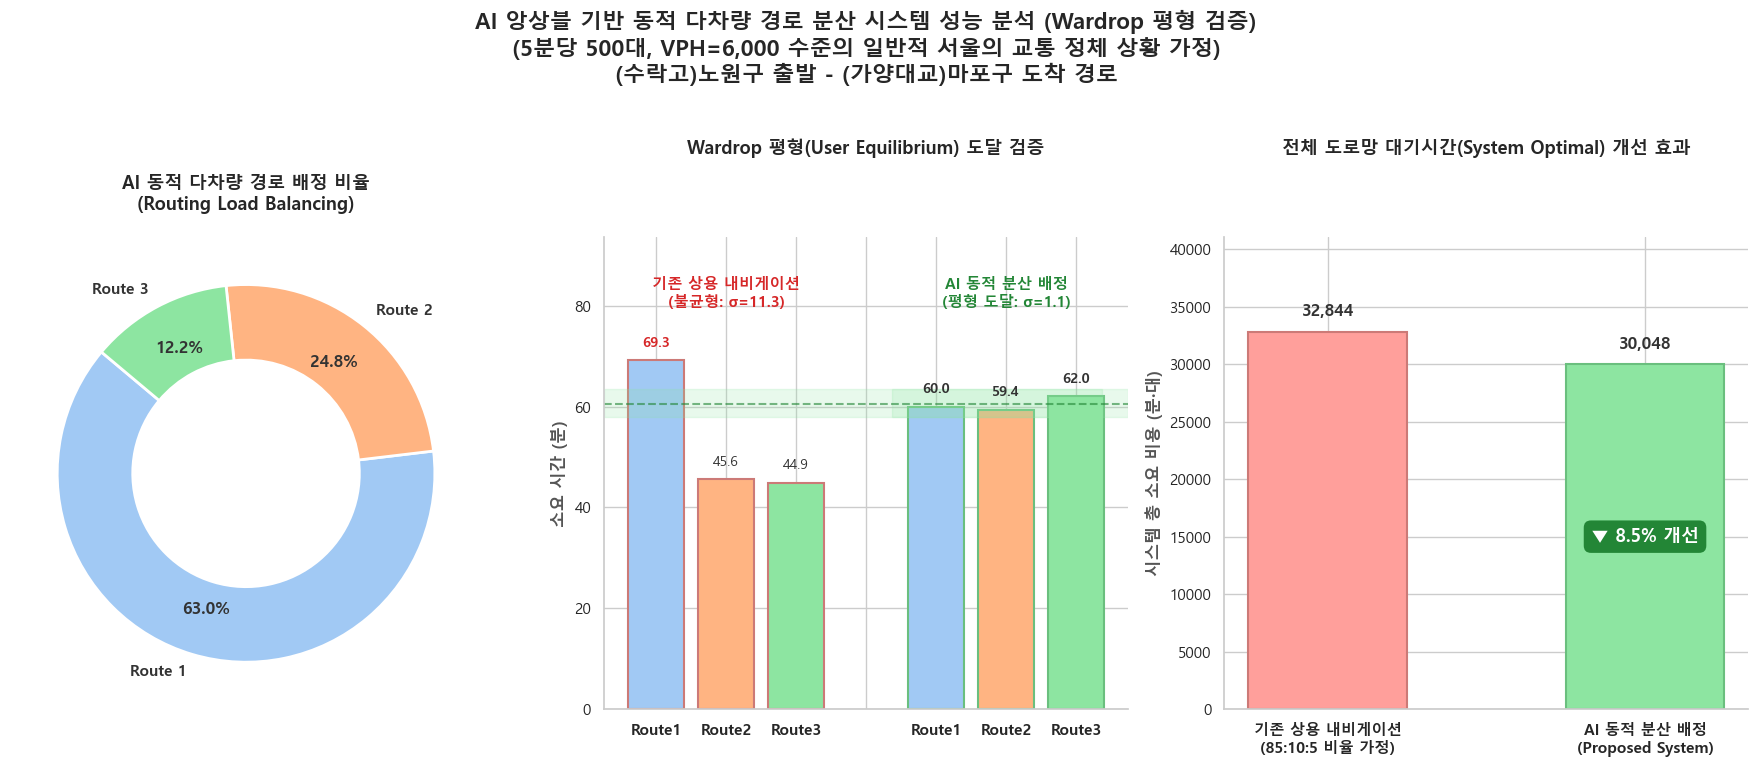

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import platform

# -----------------------------------------------------------
# 1. 세련된 디자인 테마 및 한글 폰트 완벽 세팅
# -----------------------------------------------------------
# Seaborn의 모던한 배경 테마 적용 (폰트 설정 전에 해야 함)
sns.set_theme(style="whitegrid")

# 운영체제별 한글 폰트 자동 설정
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin': # Mac
    plt.rcParams['font.family'] = 'AppleGothic'
else: # Linux (구글 코랩 등)
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지

def plot_routing_performance_final(routing_result, n_vehicles=500, save_path='report_dashboard_final.png'):
    paths_info = routing_result['k_paths_info']
    path_strs = [f"Route {i+1}" for i in range(len(paths_info))]
    base_costs = [info['cost'] for info in paths_info]
    assigned_vehicles = [info['assigned'] for info in paths_info]
    
    congested_costs = []
    for info in paths_info:
        path_key = ' → '.join(info['path'])
        congested_costs.append(routing_result['path_distribution'][path_key]['혼잡 반영 비용'])

    # 상용 내비게이션(85:10:5) 모사 계산
    legacy_ratio = [0.85, 0.10, 0.05] 
    legacy_assigned = [int(n_vehicles * r) for r in legacy_ratio]
    
    alpha, capacity, bpr_beta = 1.0, 670.0, 5.0       
    legacy_costs = []
    for i in range(len(path_strs)):
        vc = (legacy_assigned[i] * alpha) / capacity 
        bpr_multiplier = 1.0 + 0.15 * (vc ** bpr_beta)
        speed_drop_factor = max(1.0 - (vc * 0.8), 0.1) 
        legacy_costs.append(base_costs[i] * bpr_multiplier / speed_drop_factor)
    
    total_system_cost_distributed = sum(assigned_vehicles[i] * congested_costs[i] for i in range(len(path_strs)))
    total_system_cost_legacy = sum(legacy_assigned[i] * legacy_costs[i] for i in range(len(path_strs)))

    # 표준편차 계산 (평형의 척도)
    legacy_std = np.std(legacy_costs)
    ai_std = np.std(congested_costs)

    # -----------------------------------------------------------
    # 그래프 캔버스 설정
    # -----------------------------------------------------------
    fig = plt.figure(figsize=(18, 7.5)) 
    fig.suptitle('AI 앙상블 기반 동적 다차량 경로 분산 시스템 성능 분석 (Wardrop 평형 검증)\n(5분당 500대, VPH=6,000 수준의 일반적 서울의 교통 정체 상황 가정)\n(수락고)노원구 출발 - (가양대교)마포구 도착 경로', 
                 fontsize=16, fontweight='bold', y=1.02)

    # [1] 도넛 차트
    ax1 = plt.subplot(1, 3, 1)
    pie_colors = sns.color_palette("pastel", len(path_strs))
    wedges, texts, autotexts = ax1.pie(assigned_vehicles, labels=path_strs, autopct='%1.1f%%',
                                       startangle=140, colors=pie_colors, pctdistance=0.75,
                                       wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
    plt.setp(autotexts, size=12, weight="bold", color="#333333")
    plt.setp(texts, size=11, color="#333333", weight="bold")
    ax1.set_title("AI 동적 다차량 경로 배정 비율\n(Routing Load Balancing)", fontsize=13, fontweight='bold', pad=20)

    # -----------------------------------------------------------
    # [2] Wardrop 평형 (모델별 그룹화 및 표준편차 입증)
    # -----------------------------------------------------------
    ax2 = plt.subplot(1, 3, 2)

    
    # 데이터 재구성: [상용 3개, 빈칸, AI 3개]
    plot_data = legacy_costs + [0] + congested_costs
    plot_labels = ['Route1', 'Route2', 'Route3', '', 'Route1', 'Route2', 'Route3']
    plot_colors = list(pie_colors) + [(0,0,0,0)] + list(pie_colors)
    edge_colors = ['#cc7a77']*3 + [(0,0,0,0)] + ['#6abf7e']*3 # 빨강계열 테두리 vs 초록계열 테두리
    
    bars = ax2.bar(range(len(plot_data)), plot_data, color=plot_colors, edgecolor=edge_colors, linewidth=1.5)
    
    ax2.set_ylabel('소요 시간 (분)', fontweight='bold', color='#555555')
    ax2.set_title("Wardrop 평형(User Equilibrium) 도달 검증", fontsize=13, fontweight='bold', pad=60)
    ax2.set_xticks(range(len(plot_labels)))
    ax2.set_xticklabels(plot_labels, fontweight='bold')
    ax2.set_ylim(0, max(legacy_costs) * 1.35)

    # 상단 그룹 텍스트 (표준편차 포함)
    ax2.text(1, max(legacy_costs) * 1.15, f"기존 상용 내비게이션\n(불균형: σ={legacy_std:.1f})", 
             ha='center', color='#d62728', fontweight='bold', fontsize=11)
    
    ax2.text(5, max(legacy_costs) * 1.15, f"AI 동적 분산 배정\n(평형 도달: σ={ai_std:.1f})", 
             ha='center', color='#238636', fontweight='bold', fontsize=11)
    
    # 평형 밴드 및 화살표 추가
    mean_ai = np.mean(congested_costs)
    ax2.axhspan(min(congested_costs)-1.5, max(congested_costs)+1.5, xmin=0.55, xmax=0.95, color='#8de5a1', alpha=0.2)

    min_eq = min(congested_costs) - 1.5
    max_eq = max(congested_costs) + 1.5
    ax2.axhspan(min_eq, max_eq, color='#8de5a1', alpha=0.2, label='Wardrop 평형 밴드')
    ax2.axhline(np.mean(congested_costs), color='#238636', linestyle='--', linewidth=1.5, alpha=0.6)


    # 막대 위 수치 텍스트 표시
    for i, b in enumerate(bars):
        if plot_data[i] > 0:
            color_text = '#d62728' if i < 3 and plot_data[i] == max(legacy_costs) else '#333333'
            weight_text = 'bold' if i >= 4 or i == 0 else 'normal'
            ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f"{plot_data[i]:.1f}", 
                     ha='center', va='bottom', fontsize=10, fontweight=weight_text, color=color_text)

    # -----------------------------------------------------------
    # [3] 시스템 총 비용 개선 효과
    # -----------------------------------------------------------
    ax3 = plt.subplot(1, 3, 3)
    bars = ax3.bar(['기존 상용 내비게이션\n(85:10:5 비율 가정)', 'AI 동적 분산 배정\n(Proposed System)'],
                   [total_system_cost_legacy, total_system_cost_distributed],
                   color=['#ff9f9b', '#8de5a1'], edgecolor=['#cc7a77', '#6abf7e'], linewidth=1.5, width=0.5)

    ax3.set_ylabel('시스템 총 소요 비용 (분·대)', fontweight='bold', color='#555555')
    ax3.set_title("전체 도로망 대기시간(System Optimal) 개선 효과", fontsize=13, fontweight='bold', pad=60)
    ax3.set_ylim(0, total_system_cost_legacy * 1.25)
    plt.xticks(fontweight='bold')

    for i, bar in enumerate(bars):
        yval = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2, yval + (total_system_cost_legacy*0.03), f"{yval:,.0f}", 
                 ha='center', va='bottom', fontsize=12, fontweight='bold', color='#333333')
    
    improvement_rate = (total_system_cost_legacy - total_system_cost_distributed) / total_system_cost_legacy * 100
    ax3.text(1, total_system_cost_distributed / 2, f"▼ {improvement_rate:.1f}% 개선", 
             ha='center', va='center', color='white', fontweight='bold', fontsize=13, 
             bbox=dict(facecolor='#238636', edgecolor='none', pad=8, boxstyle='round,pad=0.4'))

    # 테두리 깔끔하게 제거
    sns.despine(fig)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"📊 그래프가 고해상도 이미지로 저장되었습니다: {os.path.abspath(save_path)}")
    plt.show()

# 실행 (600대 데이터 적용)
# 새로 캡처해주신 화면(N7 -> N1)의 실제 결과값 하드코딩
real_result = {
    'k_paths_info': [
        {'path': ['N7', 'N6', 'N5', 'N2', 'N1'], 'cost': 33.6, 'prob': 0.63, 'assigned': 315},
        {'path': ['N7', 'N6', 'N4', 'N3', 'N2', 'N1'], 'cost': 42.9, 'prob': 0.25, 'assigned': 124},
        {'path': ['N7', 'N6', 'N5', 'N4', 'N3', 'N2', 'N1'], 'cost': 43.6, 'prob': 0.12, 'assigned': 61}
    ],
    'path_distribution': {
        'N7 → N6 → N5 → N2 → N1': {'혼잡 반영 비용': 60.0},
        'N7 → N6 → N4 → N3 → N2 → N1': {'혼잡 반영 비용': 59.4},
        'N7 → N6 → N5 → N4 → N3 → N2 → N1': {'혼잡 반영 비용': 62.0}
    }
}

# 그래프 출력 함수 호출 시 n_vehicles를 500으로 맞추어 실행
plot_routing_performance_final(real_result, n_vehicles=500, save_path='report_dashboard_N7_to_N1.png')